# Laboratorio: SVM con margen suave y selección de kernel

En este laboratorio usamos `SVC` de scikit-learn, que implementa la SVM de margen suave:

$$\min_{w, b, \xi} \; \frac{1}{2}\|w\|^2 + C \sum_{i=1}^m \xi_i \quad \text{sujeto a} \quad y^{(i)}(w^T \phi(x^{(i)}) + b) \ge 1 - \xi_i, \; \xi_i \ge 0.$$

Sus parámetros principales son `C`, `kernel` y, para el kernel gaussiano, `gamma` $= 1/(2\sigma^2)$.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


## 1. Visualizar la frontera

Usamos datos en forma de medialuna, que no se pueden separar con una recta. La función `graficar` dibuja la frontera ($w^T\phi(x) + b = 0$), las rectas del margen ($\pm 1$) y marca los vectores de soporte.

In [14]:
datos = pd.read_csv("moons.csv")
X, y = datos[["x1", "x2"]].to_numpy(), datos["y"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)


def graficar(modelo, X, y, ax, titulo=""):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    Z = modelo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[0.8, 1.5, 0.8])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15)
    sv = modelo.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=60, facecolors="none", edgecolors="k", linewidths=0.8)
    ax.set_title(f"{titulo}\n{len(sv)} vectores de soporte")

### 1.1. Tres kernels

Comparamos el kernel lineal, el polinomial $K(x, z) = (\gamma\, x^T z + c)^3$ y el gaussiano.

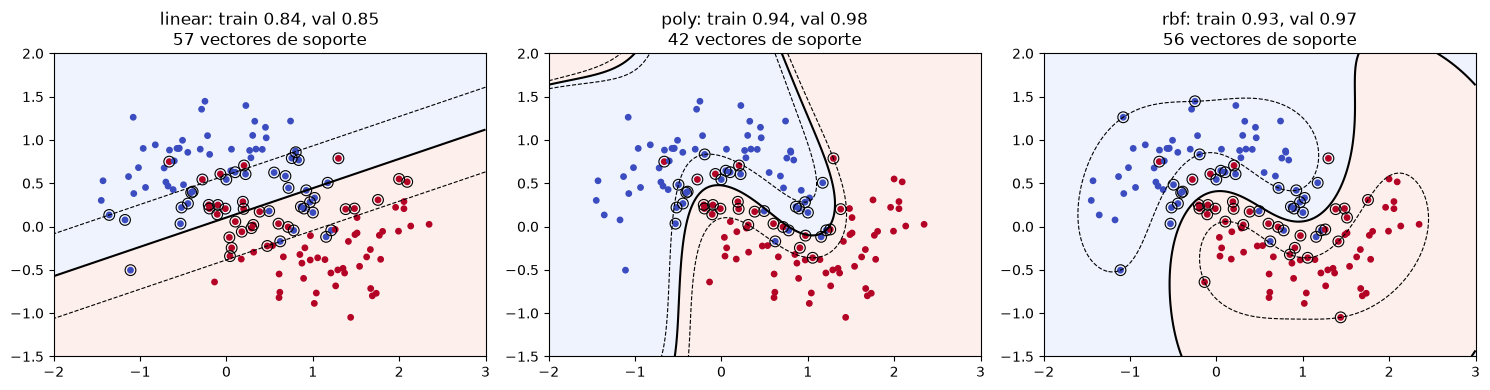

In [15]:
kernels = [
    SVC(kernel="linear", C=1),
    SVC(kernel="poly", degree=4, coef0=1, C=1),
    SVC(kernel="rbf", gamma=1, C=1),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for modelo, ax in zip(kernels, axes):
    modelo.fit(X_train, y_train)
    graficar(modelo, X_train, y_train, ax,
             f"{modelo.kernel}: train {modelo.score(X_train, y_train):.2f}, val {modelo.score(X_test, y_test):.2f}")
plt.tight_layout()

### 1.2. Efecto de C

Con `C` pequeño el margen es ancho y muchos ejemplos quedan dentro de él. Con `C` grande nos acercamos al margen duro.

**Pregunta:** ¿cómo cambia el número de vectores de soporte con `C`? ¿Por qué?

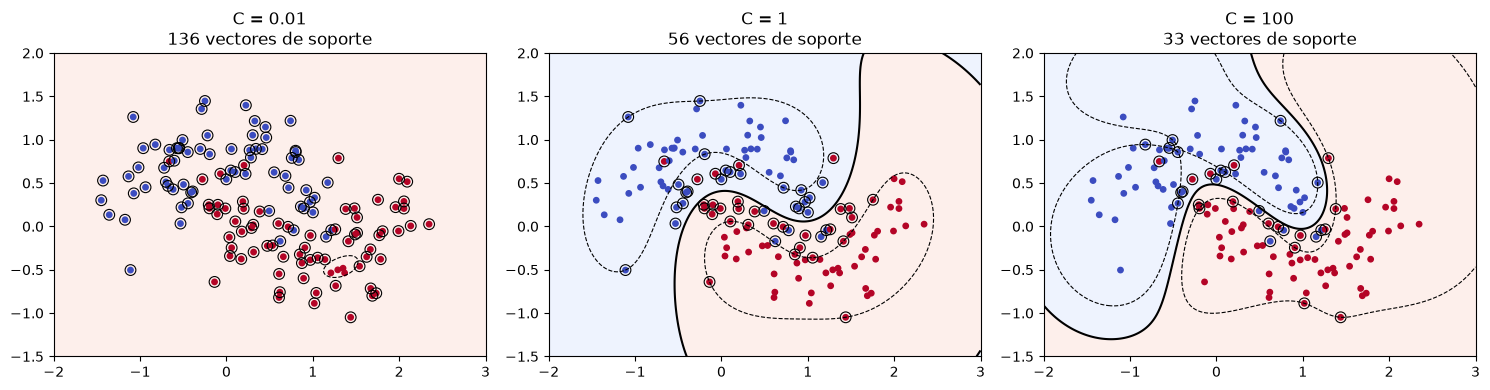

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for C, ax in zip([0.01, 1, 100], axes):
    modelo = SVC(kernel="rbf", gamma=1, C=C).fit(X_train, y_train)
    graficar(modelo, X_train, y_train, ax, f"C = {C}")
plt.tight_layout()

### 1.3. Efecto de gamma (es decir, de $\sigma$)

**Pregunta:** ¿con qué valor de `gamma` hay overfitting? Compare la exactitud de entrenamiento y de validación.

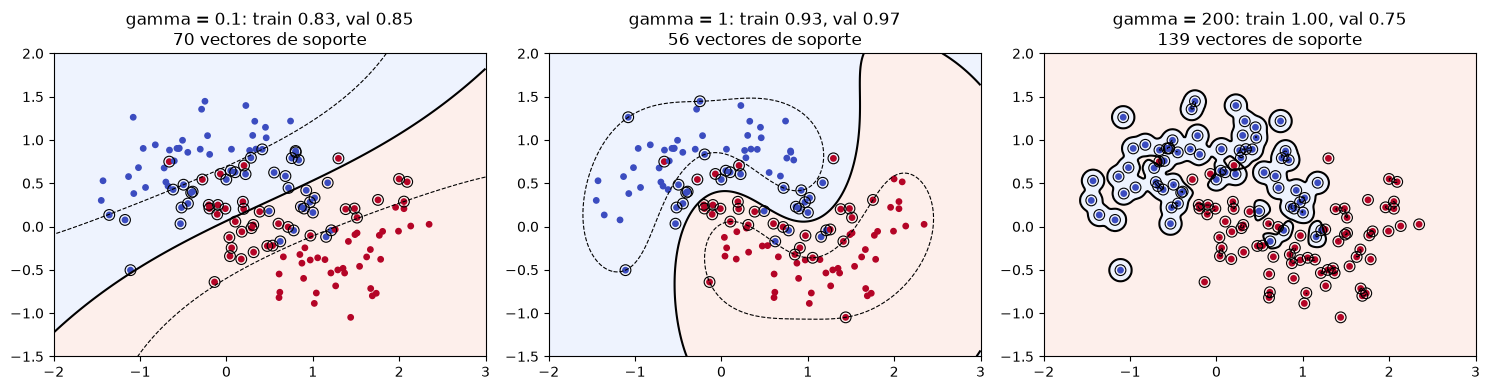

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for gamma, ax in zip([0.1, 1, 200], axes):
    modelo = SVC(kernel="rbf", gamma=gamma, C=1).fit(X_train, y_train)
    graficar(modelo, X_train, y_train, ax,
             f"gamma = {gamma}: train {modelo.score(X_train, y_train):.2f}, val {modelo.score(X_test, y_test):.2f}")
plt.tight_layout()

## 2. Conexión con el problema dual

Después de entrenar, `SVC` guarda:

- `support_vectors_`: los ejemplos con $\alpha_i > 0$.
- `dual_coef_`: los productos $\alpha_i y^{(i)}$ (con $y \in \{-1, 1\}$) de esos ejemplos.
- `intercept_`: el valor de $b$.

Verifiquemos que la predicción es $\sum_i \alpha_i y^{(i)} K(x^{(i)}, x) + b$ y que $0 \le \alpha_i \le C$.

In [18]:
C, gamma = 1, 1
modelo = SVC(kernel="rbf", gamma=gamma, C=C).fit(X_train, y_train)

alpha_y = modelo.dual_coef_.ravel()
K = rbf_kernel(X_test, modelo.support_vectors_, gamma=gamma)
score_manual = K @ alpha_y + modelo.intercept_[0]

print("¿Coincide con decision_function?", np.allclose(score_manual, modelo.decision_function(X_test)))

alpha = np.abs(alpha_y)
print(f"Vectores de soporte: {len(alpha)} de {len(X_train)}")
print(f"Con alpha = C (dentro del margen o mal clasificados): {np.sum(np.isclose(alpha, C))}")
print(f"Con 0 < alpha < C (sobre el margen): {np.sum(alpha < C - 1e-6)}")
print("Suma de alpha_i y_i (debe ser 0):", round(alpha_y.sum(), 10))

¿Coincide con decision_function? True
Vectores de soporte: 56 de 140
Con alpha = C (dentro del margen o mal clasificados): 43
Con 0 < alpha < C (sobre el margen): 13
Suma de alpha_i y_i (debe ser 0): 0.0


## 3. Selección del kernel y sus parámetros

Usamos el dataset de cáncer de mama de Wisconsin (30 features, 569 ejemplos). Escogemos el kernel, `C` y `gamma` con validación cruzada sobre el conjunto de entrenamiento, y usamos el conjunto de prueba una sola vez al final.

El `Pipeline` estandariza las features dentro de cada partición de la validación cruzada, usando solo los datos de entrenamiento de esa partición, para evitar data leakage.

In [25]:
datos = pd.read_csv("breast_cancer.csv")
X, y = datos.drop(columns="target").to_numpy(), datos["target"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

pipeline = make_pipeline(StandardScaler(), SVC())
grilla = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["poly"], "svc__degree": [2, 3], "svc__coef0": [1], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.01, 0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]},
]
busqueda = GridSearchCV(pipeline, grilla, cv=5).fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
print(f"Exactitud de validación cruzada: {busqueda.best_score_:.3f}")

Mejores parámetros: {'svc__C': 0.1, 'svc__kernel': 'linear'}
Exactitud de validación cruzada: 0.988


Mejor resultado de cada kernel:

In [26]:
res = pd.DataFrame(busqueda.cv_results_)
res["kernel"] = res["param_svc__kernel"]
mejores = res.loc[res.groupby("kernel")["mean_test_score"].idxmax(), ["kernel", "params", "mean_test_score"]]
mejores

,kernel,params,mean_test_score
1,linear,"{'svc__C': 0.1, 'svc__kernel': 'linear'}",0.988263
9,poly,"{'svc__C': 1, 'svc__coef0': 1, 'svc__degree': ...",0.983557
31,rbf,"{'svc__C': 100, 'svc__gamma': 0.001, 'svc__ker...",0.988263


Evaluación final, una sola vez, sobre el conjunto de prueba:

In [ ]:
print(f"Exactitud de prueba: {busqueda.score(X_test, y_test):.3f}")

Exactitud de prueba: 0.958


**Preguntas:**

1. ¿Qué kernel ganó? ¿La diferencia con los demás es grande? Con 30 features y pocos ejemplos, ¿le sorprende el resultado?
2. Repita la búsqueda sin `StandardScaler`. ¿Qué kernel se ve más afectado y por qué?
3. ¿Por qué no es correcto escoger `C` y `gamma` mirando la exactitud sobre el conjunto de prueba?